In [1]:
!pip -q install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load the UCI Online Retail dataset
online_retail = fetch_ucirepo(id=352)

df = online_retail.data.features.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (541909, 6)


,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
# Remove rows without Customer ID
df = df.dropna(subset=['CustomerID'])

# Remove cancelled transactions
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Keep only positive quantity and price
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Convert date column
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Calculate total amount
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

print("Data cleaning completed!")
print("Cleaned dataset shape:", df.shape)

display(df.head())

KeyError: 'InvoiceNo'

In [4]:
print(df.columns.tolist())

['Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [5]:
display(df.head())

,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [6]:
# Remove rows with missing CustomerID
df = df.dropna(subset=['CustomerID'])

# Keep only positive quantities and prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Convert InvoiceDate into datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Calculate total transaction amount
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

print("Data cleaning completed successfully!")
print("Cleaned dataset shape:", df.shape)

display(df.head())

Data cleaning completed successfully!
Cleaned dataset shape: (397884, 7)


,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [7]:
# Set reference date
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM values
rfm = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate',
             lambda x: (reference_date - x.max()).days),

    Frequency=('InvoiceDate', 'nunique'),

    Monetary=('TotalAmount', 'sum')
).reset_index()

print("RFM calculation completed!")
display(rfm.head())

RFM calculation completed!


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [8]:
print("Total customers:", rfm['CustomerID'].nunique())
print(rfm.describe())

Total customers: 4338
         CustomerID      Recency    Frequency       Monetary
count   4338.000000  4338.000000  4338.000000    4338.000000
mean   15300.408022    92.536422     4.250807    2054.266460
std     1721.808492   100.014169     7.635202    8989.230441
min    12346.000000     1.000000     1.000000       3.750000
25%    13813.250000    18.000000     1.000000     307.415000
50%    15299.500000    51.000000     2.000000     674.485000
75%    16778.750000   142.000000     5.000000    1661.740000
max    18287.000000   374.000000   210.000000  280206.020000


In [9]:
# Calculate RFM scores

# Recency: lower days are better
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: higher is better
rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher spending is better
rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Calculate total RFM score
rfm['RFM_Score'] = (
    rfm['R_Score'] +
    rfm['F_Score'] +
    rfm['M_Score']
)

# Assign customer segments
def assign_segment(score):
    if score >= 12:
        return 'Champions'
    elif score >= 9:
        return 'Loyal Customers'
    elif score >= 6:
        return 'Potential Customers'
    else:
        return 'At Risk / Lost'

rfm['Segment'] = rfm['RFM_Score'].apply(assign_segment)

print("RFM scoring completed!")

display(rfm.head(10))

RFM scoring completed!


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,326,1,77183.60,1,1,5,7,Potential Customers
1,12347.0,2,7,4310.00,5,5,5,15,Champions
2,12348.0,75,4,1797.24,2,4,4,10,Loyal Customers
3,12349.0,19,1,1757.55,4,1,4,9,Loyal Customers
4,12350.0,310,1,334.40,1,1,2,4,At Risk / Lost
5,12352.0,36,8,2506.04,3,5,5,13,Champions
6,12353.0,204,1,89.00,1,1,1,3,At Risk / Lost
7,12354.0,232,1,1079.40,1,1,4,6,Potential Customers
8,12355.0,214,1,459.40,1,1,2,4,At Risk / Lost
9,12356.0,23,3,2811.43,4,3,5,12,Champions


In [10]:
print("CUSTOMER SEGMENT DISTRIBUTION")

print(rfm['Segment'].value_counts())

print("\nTOTAL CUSTOMERS:", len(rfm))

CUSTOMER SEGMENT DISTRIBUTION
Segment
Champions              1245
Potential Customers    1192
Loyal Customers        1016
At Risk / Lost          885
Name: count, dtype: int64

TOTAL CUSTOMERS: 4338


In [11]:
# Select RFM columns
X = rfm[['Recency', 'Frequency', 'Monetary']].copy()

# Apply log transformation
X = np.log1p(X)

# Standardize the values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")

print("\nCluster Distribution:")
print(rfm['Cluster'].value_counts().sort_index())

K-Means clustering completed!

Cluster Distribution:
Cluster
0    1608
1     842
2     711
3    1177
Name: count, dtype: int64


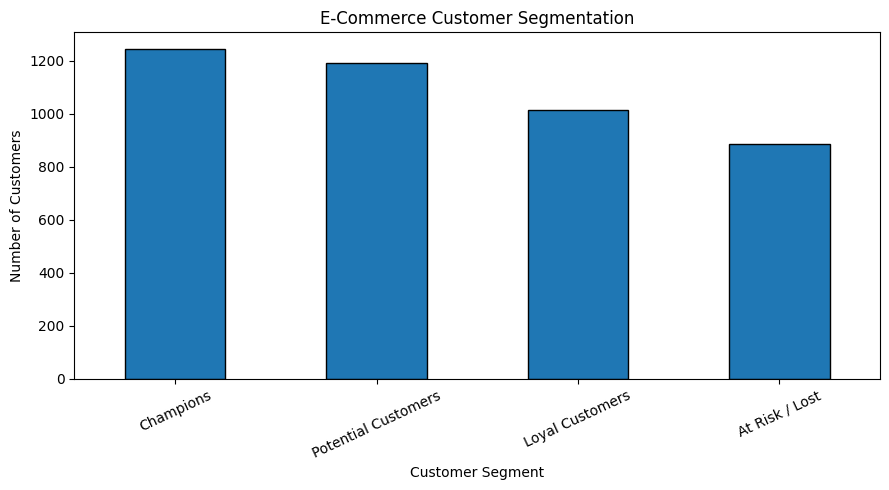

In [12]:
plt.figure(figsize=(9, 5))

rfm['Segment'].value_counts().plot(
    kind='bar',
    edgecolor='black'
)

plt.title('E-Commerce Customer Segmentation')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig('customer_segments.png', dpi=150)
plt.show()

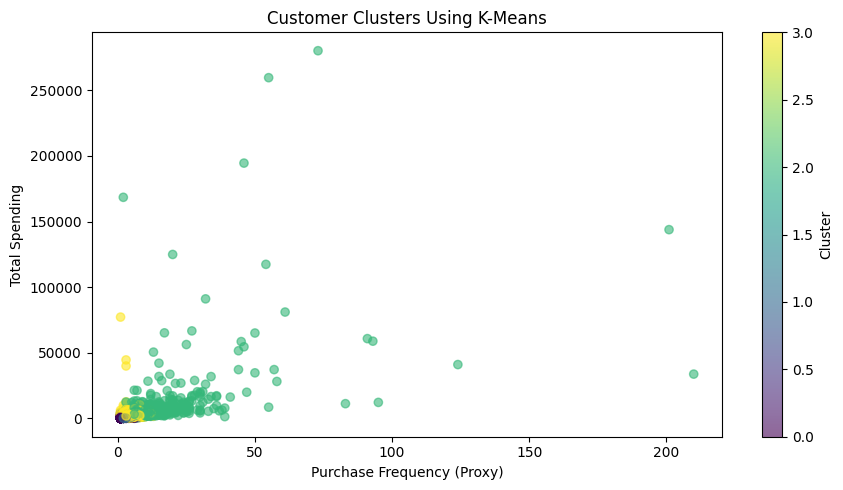

In [13]:
plt.figure(figsize=(9, 5))

plt.scatter(
    rfm['Frequency'],
    rfm['Monetary'],
    c=rfm['Cluster'],
    cmap='viridis',
    alpha=0.6
)

plt.title('Customer Clusters Using K-Means')
plt.xlabel('Purchase Frequency (Proxy)')
plt.ylabel('Total Spending')
plt.colorbar(label='Cluster')
plt.tight_layout()

plt.savefig('customer_clusters.png', dpi=150)
plt.show()

In [14]:
cluster_summary = rfm.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Average_Monetary=('Monetary', 'mean')
).round(2)

display(cluster_summary)

,Customers,Average_Recency,Average_Frequency,Average_Monetary
Cluster,,,,
0,1608,183.78,1.32,350.93
1,842,18.76,2.09,539.14
2,711,12.01,13.65,8100.04
3,1177,69.31,4.12,1813.10


In [15]:
# Save RFM customer data
rfm.to_csv('customer_rfm_segments.csv', index=False)

# Save customer segment summary
segment_summary = rfm.groupby('Segment').agg(
    Customers=('CustomerID', 'count'),
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Average_Monetary=('Monetary', 'mean')
).round(2)

segment_summary.to_csv('segment_summary.csv')

# Save cluster summary
cluster_summary.to_csv('cluster_summary.csv')

print("All project files saved successfully!")

All project files saved successfully!


In [16]:
from google.colab import files

for filename in [
    'customer_rfm_segments.csv',
    'segment_summary.csv',
    'cluster_summary.csv',
    'customer_segments.png',
    'customer_clusters.png'
]:
    files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

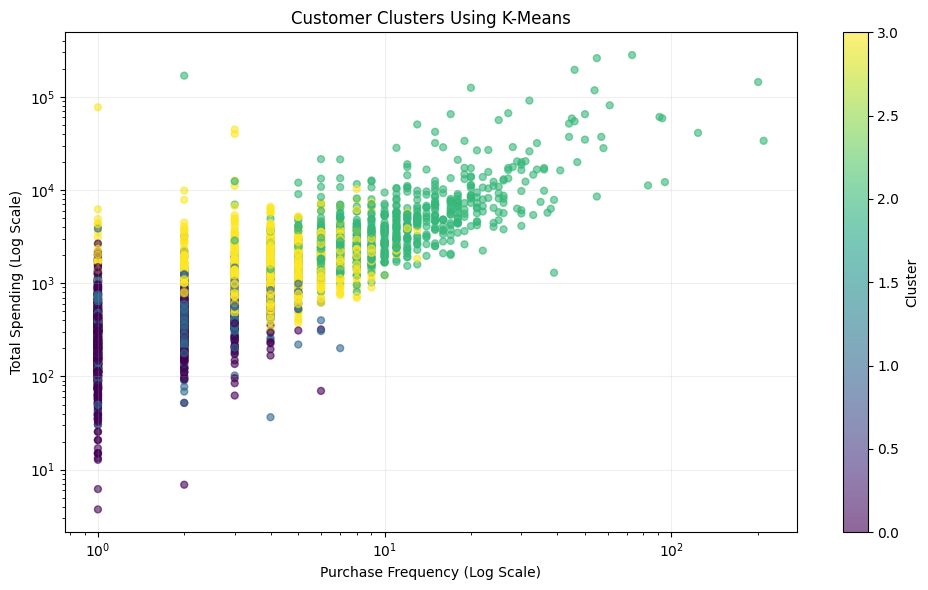

In [17]:
plt.figure(figsize=(10, 6))

plt.scatter(
    rfm['Frequency'],
    rfm['Monetary'],
    c=rfm['Cluster'],
    cmap='viridis',
    alpha=0.6,
    s=25
)

plt.xscale('log')
plt.yscale('log')

plt.title('Customer Clusters Using K-Means')
plt.xlabel('Purchase Frequency (Log Scale)')
plt.ylabel('Total Spending (Log Scale)')

plt.colorbar(label='Cluster')
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig('customer_clusters.png', dpi=150)
plt.show()

In [18]:
cluster_summary = rfm.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Average_Monetary=('Monetary', 'mean')
).round(2)

display(cluster_summary)

,Customers,Average_Recency,Average_Frequency,Average_Monetary
Cluster,,,,
0,1608,183.78,1.32,350.93
1,842,18.76,2.09,539.14
2,711,12.01,13.65,8100.04
3,1177,69.31,4.12,1813.10


In [19]:
print(cluster_summary.to_string())

         Customers  Average_Recency  Average_Frequency  Average_Monetary
Cluster                                                                 
0             1608           183.78               1.32            350.93
1              842            18.76               2.09            539.14
2              711            12.01              13.65           8100.04
3             1177            69.31               4.12           1813.10


In [20]:
import os
import zipfile

# Files to include in the project
project_files = [
    'customer_rfm_segments.csv',
    'segment_summary.csv',
    'cluster_summary.csv',
    'customer_segments.png',
    'customer_clusters.png'
]

# Check which files exist
for filename in project_files:
    if os.path.exists(filename):
        print("Found:", filename)
    else:
        print("Missing:", filename)

# Create a ZIP file
with zipfile.ZipFile(
    'Ecommerce_RFM_Project.zip',
    'w',
    zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in project_files:
        if os.path.exists(filename):
            zip_file.write(filename)

print("\nZIP file created successfully!")

Found: customer_rfm_segments.csv
Found: segment_summary.csv
Found: cluster_summary.csv
Found: customer_segments.png
Found: customer_clusters.png

ZIP file created successfully!


In [21]:
from google.colab import files

files.download('Ecommerce_RFM_Project.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>